In [1]:
# Import libraries
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import time

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as imbpipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, RocCurveDisplay
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

**Ans to Q1(b)(i)**

Common techniques for handling missing data include deletion, simple statistical imputation (filling with the column mean, median, or mode), k-nearest-neighbors imputation etc. Deleting rows isn’t viable here: only 591 of the 60,000 training rows are complete, and 169 of the 170 features have at least one missing value. I am choosing  median imputation because the features are heavily skewed with extreme outliers.

**Ans to Q1(b)(ii)**

In [2]:
import pandas as pd
from sklearn.impute import SimpleImputer

# drop 20 lines and get NaN
df_train = pd.read_csv('aps_failure_training_set.csv', skiprows=20, na_values='na')
df_test = pd.read_csv('aps_failure_test_set.csv', skiprows=20, na_values='na')

# create test and train dataset
x_train = df_train.drop(columns=['class'])
y_train = df_train['class']

x_test = df_test.drop(columns=['class'])
y_test = df_test['class']

# Apply Median Imputation
imputer = SimpleImputer(strategy='median')

# Fit the imputer ONLY on the training data, then transform both sets
x_train_imputed = pd.DataFrame(imputer.fit_transform(x_train), columns=x_train.columns)
x_test_imputed = pd.DataFrame(imputer.transform(x_test), columns=x_test.columns)

# Verify the missing values are gone
print(f"Missing values before imputation (train): {x_train.isna().sum().sum()}")
print(f"Missing values after imputation (train): {x_train_imputed.isna().sum().sum()}")

# 1(b)(ii): Calculate Coefficient of Variation (CV)
# Calculate sample standard deviation (s) and sample mean (m)
s = x_train_imputed.std()
m = x_train_imputed.mean()

# Calculate CV = s / m
cv = s / m
cv.sort_values(ascending=False)

# Display a summary and the CV values for the first 10 features
print("Summary of CV for all 170 features:")
print(cv.describe())

with pd.option_context('display.max_rows', 200):
    display(cv.sort_values(ascending=False).to_frame(name='CV'))

Missing values before imputation (train): 850015
Missing values after imputation (train): 0
Summary of CV for all 170 features:
count    170.000000
mean      20.153912
std       41.302794
min        0.000000
25%        2.600360
50%        4.880633
75%       17.231787
max      244.887517
dtype: float64


,CV
cf_000,244.887517
co_000,244.507385
ad_000,244.322816
cs_009,237.930554
dh_000,123.216097
dj_000,117.494225
ag_000,92.917755
as_000,87.332500
ay_009,84.733735
ak_000,80.424975


**Ans to Q1(b)(iii)**

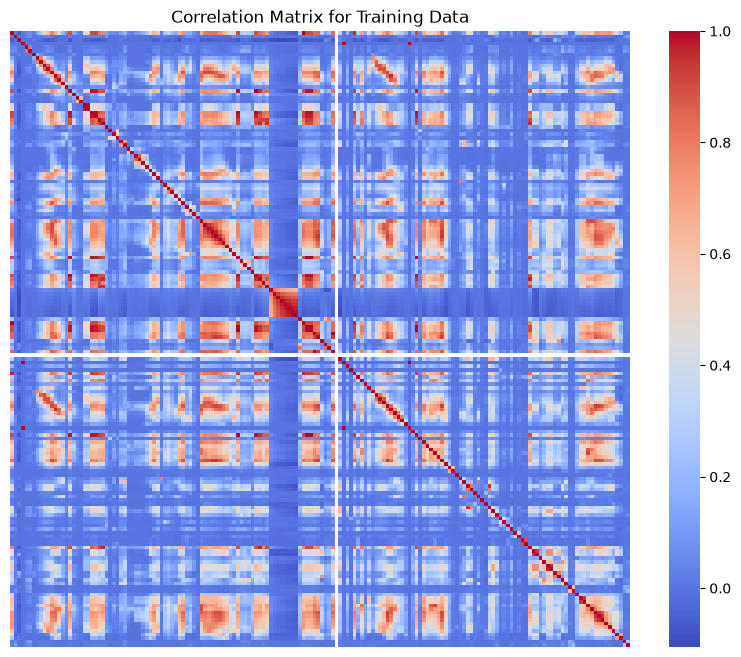

In [3]:
corr_matrix = x_train_imputed.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, cmap='coolwarm', xticklabels=False, yticklabels=False)
plt.title("Correlation Matrix for Training Data")
plt.show()

**Ans to Q1(b)(iv)**

In [ ]:
top_13_features = cv.sort_values(ascending=False).head(13).index.tolist()
plot_data = x_train_imputed[top_13_features].copy()
plot_data['class'] = y_train
# Calculate running time
start_time = time.time()
# Create pairplot (setting diag_kind to None to save running time)
pos_rows = plot_data[plot_data['class'] == 'pos']           # all failed trucks
neg_sample = plot_data[plot_data['class'] == 'neg'].sample(n=1000, random_state=69)  # 1000 random healthy trucks
small_data = pd.concat([pos_rows, neg_sample])              # put them together
pairplots = sns.pairplot(small_data, vars=top_13_features, hue='class', diag_kind=None)
pairplots.set(xscale="log", yscale="log")
plt.show()
print("--- %s seconds ---" % (time.time() - start_time))

We cannot draw conclusion from the scatter plot with confidence. The plots suggest some features might matter. However, the two classes overlap heavily, and looking at plots isn’t a statistical test. A model or test is needed to judge significance properly.

In [ ]:
plt.figure(figsize=(15, 10))
for i, feature in enumerate(top_13_features):
    plt.subplot(4, 4, i+1)
    sns.boxplot(x='class', y=feature, data=plot_data)
    plt.yscale('symlog')
    plt.title(f'Boxplot: {feature}')
plt.tight_layout()
plt.show()

**1b(v)**

In [ ]:
display(y_train.value_counts())

The dataset is heavily imbalanced towards healthy trucks.

**1(c)**

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve, accuracy_score
rf = RandomForestClassifier(oob_score=True, random_state=42, n_jobs=-1)
rf.fit(x_train_imputed, y_train)

y_train_pred = rf.predict(x_train_imputed)
y_train_prob = rf.predict_proba(x_train_imputed)[:, 1]

y_test_pred = rf.predict(x_test_imputed)
y_test_prob = rf.predict_proba(x_test_imputed)[:, 1]

print("--- TRAINING METRICS ---")
print("Confusion Matrix:\n", confusion_matrix(y_train, y_train_pred))
print(f"AUC: {roc_auc_score(y_train, y_train_prob):.5f}")
print(f"Misclassification Rate: {1 - accuracy_score(y_train, y_train_pred):.5f}")

print("\n--- TEST METRICS ---")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_test_pred))
print(f"AUC: {roc_auc_score(y_test, y_test_prob):.5f}")
test_error = 1 - accuracy_score(y_test, y_test_pred)
print(f"Misclassification Rate: {test_error:.5f}")

print("\n--- OOB vs TEST ERROR ---")
oob_error = 1 - rf.oob_score_
print(f"OOB Error Estimate: {oob_error:.5f}")
print(f"Test Error: {test_error:.5f}")

fpr_train, tpr_train, _ = roc_curve(y_train, y_train_prob, pos_label='pos')
fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob, pos_label='pos')

plt.figure(figsize=(8, 6))
plt.plot(fpr_train, tpr_train, label=f'Train ROC (AUC = {roc_auc_score(y_train, y_train_prob):.5f})')
plt.plot(fpr_test, tpr_test, label=f'Test ROC (AUC = {roc_auc_score(y_test, y_test_prob):.5f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: Random Forest (Uncompensated)')
plt.legend()
plt.show()

**1(d)**

In [ ]:
# We will be trying class weighting to compensate for class imbalance
rf_c = RandomForestClassifier(oob_score=True, random_state=42, n_jobs=-1, class_weight='balanced_subsample')
rf_c.fit(x_train_imputed, y_train)

y_train_pred_c = rf_c.predict(x_train_imputed)
y_train_prob_c = rf_c.predict_proba(x_train_imputed)[:, 1]

y_test_pred_c = rf_c.predict(x_test_imputed)
y_test_prob_c = rf_c.predict_proba(x_test_imputed)[:, 1]

print("--- TRAINING METRICS ---")
print("Confusion Matrix:\n", confusion_matrix(y_train, y_train_pred_c))
print(f"AUC: {roc_auc_score(y_train, y_train_prob_c):.5f}")
print(f"Misclassification Rate: {1 - accuracy_score(y_train, y_train_pred_c):.5f}")

print("\n--- TEST METRICS ---")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_test_pred_c))
print(f"AUC: {roc_auc_score(y_test, y_test_prob_c):.5f}")
test_error_c = 1 - accuracy_score(y_test, y_test_pred_c)
print(f"Misclassification Rate: {test_error_c:.5f}")

print("\n--- OOB vs TEST ERROR ---")
oob_error_c = 1 - rf_c.oob_score_
print(f"OOB Error Estimate: {oob_error_c:.5f}")
print(f"Test Error: {test_error_c:.5f}")

fpr_train_c, tpr_train_c, _ = roc_curve(y_train, y_train_prob_c, pos_label='pos')
fpr_test_c, tpr_test_c, _ = roc_curve(y_test, y_test_prob_c, pos_label='pos')

plt.figure(figsize=(8, 6))
plt.plot(fpr_train_c, tpr_train_c, label=f'Train ROC (AUC = {roc_auc_score(y_train, y_train_prob_c):.5f})')
plt.plot(fpr_test_c, tpr_test_c, label=f'Test ROC (AUC = {roc_auc_score(y_test, y_test_prob_c):.5f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: Random Forest (Class Weighted)')
plt.legend()
plt.show()

Here class weighting actually hurt rather than help. Here, upon changing from uncompensated to compensated, missed failures went from 106 to 164, AUC from 0.993 to 0.990, OOB went from 0.6% to 0.8%. It's because random forest works until each leaf is pure. So, it predicts its class regardless of the weight. Here, then class balance sometimes hurt.

**1(e)**

In [ ]:
le = LabelEncoder()
y_train_num = le.fit_transform(y_train)   
y_test_num = le.transform(y_test)         

xgb_model = XGBClassifier(                
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42                      
)
param_grid = {'reg_alpha': [1e-3, 1e-2, 0.1, 1, 10]}
grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',                    
    n_jobs=-1,
    verbose=1
)

print("Starting 5-Fold Grid Search...")
grid_search.fit(x_train_imputed, y_train_num)   

best_alpha = grid_search.best_params_['reg_alpha']
best_model = grid_search.best_estimator_

# FIX: 5-fold CV misclassification error for the chosen alpha
cv_acc = cross_val_score(best_model, x_train_imputed, y_train_num, cv=5, scoring='accuracy', n_jobs=-1)
cv_error_xgb = 1 - cv_acc.mean()

# Training set metrics (FIX: _xgb names, numeric labels)
y_train_pred_xgb = best_model.predict(x_train_imputed)
y_train_prob_xgb = best_model.predict_proba(x_train_imputed)[:, 1]
cm_train_xgb = confusion_matrix(y_train_num, y_train_pred_xgb)
auc_train_xgb = roc_auc_score(y_train_num, y_train_prob_xgb)
misclass_train_xgb = 1 - accuracy_score(y_train_num, y_train_pred_xgb)


y_test_pred_xgb = best_model.predict(x_test_imputed)
y_test_prob_xgb = best_model.predict_proba(x_test_imputed)[:, 1]
cm_test_xgb = confusion_matrix(y_test_num, y_test_pred_xgb)
auc_test_xgb = roc_auc_score(y_test_num, y_test_prob_xgb)
misclass_test_xgb = 1 - accuracy_score(y_test_num, y_test_pred_xgb)


print(f"Best Alpha (L1 Regularization): {best_alpha}")
print(f"5-Fold CV Error Estimate: {cv_error_xgb:.5f}")
print("\n--- TRAINING METRICS ---")
print("Confusion Matrix:\n", cm_train_xgb)
print(f"AUC: {auc_train_xgb:.5f}")
print(f"Misclassification Rate: {misclass_train_xgb:.5f}")
print("\n--- TEST METRICS ---")
print("Confusion Matrix:\n", cm_test_xgb)
print(f"AUC: {auc_test_xgb:.5f}")
print(f"Misclassification Rate: {misclass_test_xgb:.5f}")


fpr_train_xgb, tpr_train_xgb, _ = roc_curve(y_train_num, y_train_prob_xgb)
fpr_test_xgb, tpr_test_xgb, _ = roc_curve(y_test_num, y_test_prob_xgb)

plt.figure(figsize=(8, 6))
plt.plot(fpr_train_xgb, tpr_train_xgb, label=f'Train ROC (AUC = {auc_train_xgb:.5f})')
plt.plot(fpr_test_xgb, tpr_test_xgb, label=f'Test ROC (AUC = {auc_test_xgb:.5f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'ROC Curve: XGBoost (Uncompensated, Alpha={best_alpha})')
plt.legend()
plt.show()

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve, accuracy_score
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
smote = SMOTE(random_state=69)                

xgb_model_smote = XGBClassifier(               
    objective='binary:logistic',
    eval_metric='logloss',
    tree_method='hist',
    random_state=69                            
)

pipeline = ImbPipeline(steps=[('smote', smote), ('xgb', xgb_model_smote)])

param_grid = {'xgb__reg_alpha': [1e-3, 1e-2, 0.1, 1, 10]}

grid_search_smote = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring={'auc': 'roc_auc', 'acc': 'accuracy'},  
    refit='auc',                                      
    n_jobs=-1,
    verbose=2
)

print("Starting 5-Fold Grid Search with SMOTE inside the loop...")
grid_search_smote.fit(x_train_imputed, y_train_num)  

best_alpha_smote = grid_search_smote.best_params_['xgb__reg_alpha']
best_model_smote = grid_search_smote.best_estimator_


best_i = grid_search_smote.best_index_
cv_error_smote = 1 - grid_search_smote.cv_results_['mean_test_acc'][best_i]


y_train_pred_smote = best_model_smote.predict(x_train_imputed)
y_train_prob_smote = best_model_smote.predict_proba(x_train_imputed)[:, 1]
y_test_pred_smote = best_model_smote.predict(x_test_imputed)
y_test_prob_smote = best_model_smote.predict_proba(x_test_imputed)[:, 1]

auc_train_smote = roc_auc_score(y_train_num, y_train_prob_smote)
auc_test_smote = roc_auc_score(y_test_num, y_test_prob_smote)

print(f"\nBest Alpha (L1 Regularization): {best_alpha_smote}")
print(f"5-Fold CV Error Estimate: {cv_error_smote:.5f}")

print("\n--- TRAINING METRICS (SMOTE) ---")
print("Confusion Matrix:\n", confusion_matrix(y_train_num, y_train_pred_smote))
print(f"AUC: {auc_train_smote:.5f}")
print(f"Misclassification Rate: {1 - accuracy_score(y_train_num, y_train_pred_smote):.5f}")   # FIX: added

print("\n--- TEST METRICS (SMOTE) ---")
print("Confusion Matrix:\n", confusion_matrix(y_test_num, y_test_pred_smote))
print(f"AUC: {auc_test_smote:.5f}")
print(f"Misclassification Rate: {1 - accuracy_score(y_test_num, y_test_pred_smote):.5f}")

# FIX: added ROC plot
fpr_train_smote, tpr_train_smote, _ = roc_curve(y_train_num, y_train_prob_smote)
fpr_test_smote, tpr_test_smote, _ = roc_curve(y_test_num, y_test_prob_smote)

plt.figure(figsize=(8, 6))
plt.plot(fpr_train_smote, tpr_train_smote, label=f'Train ROC (AUC = {auc_train_smote:.5f})')
plt.plot(fpr_test_smote, tpr_test_smote, label=f'Test ROC (AUC = {auc_test_smote:.5f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'ROC Curve: XGBoost + SMOTE (Alpha={best_alpha_smote})')
plt.legend()
plt.show()

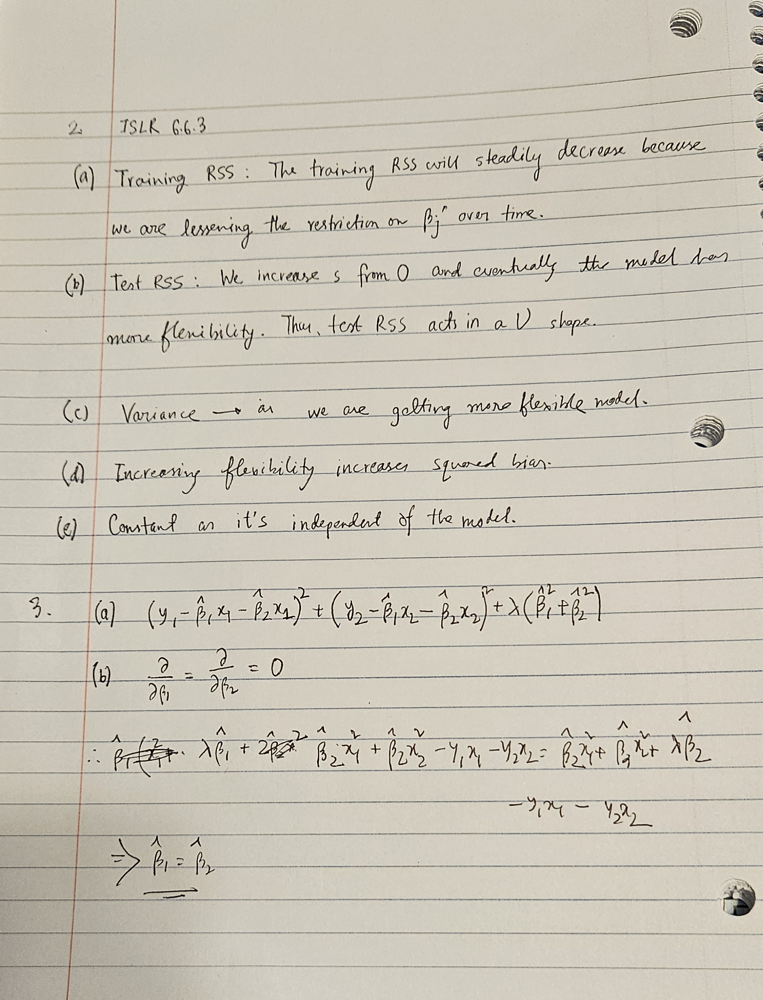

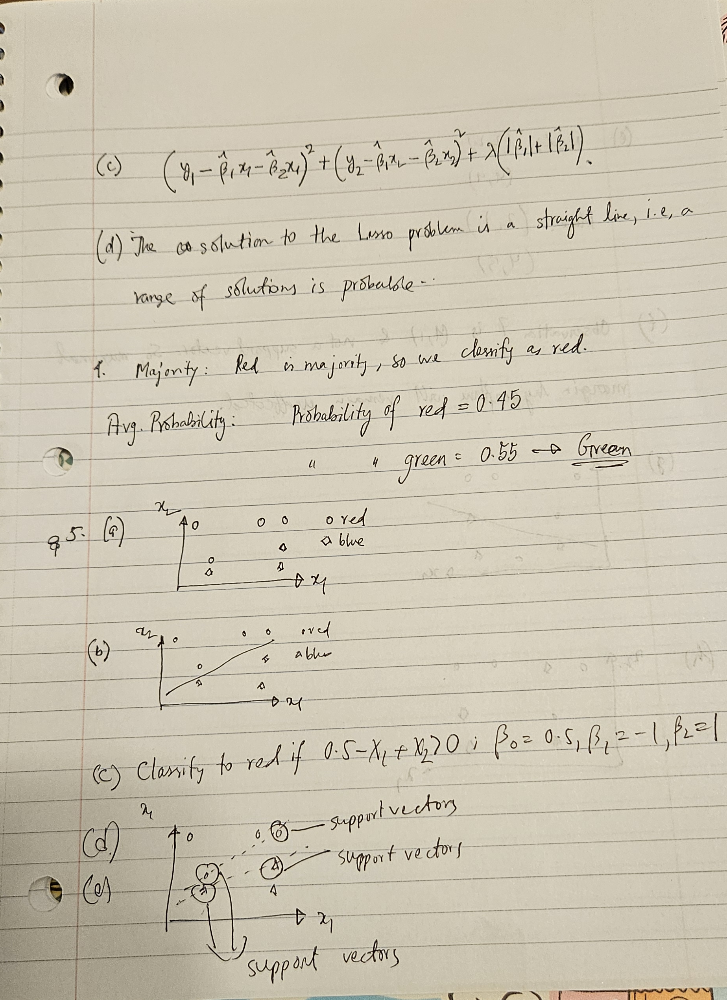

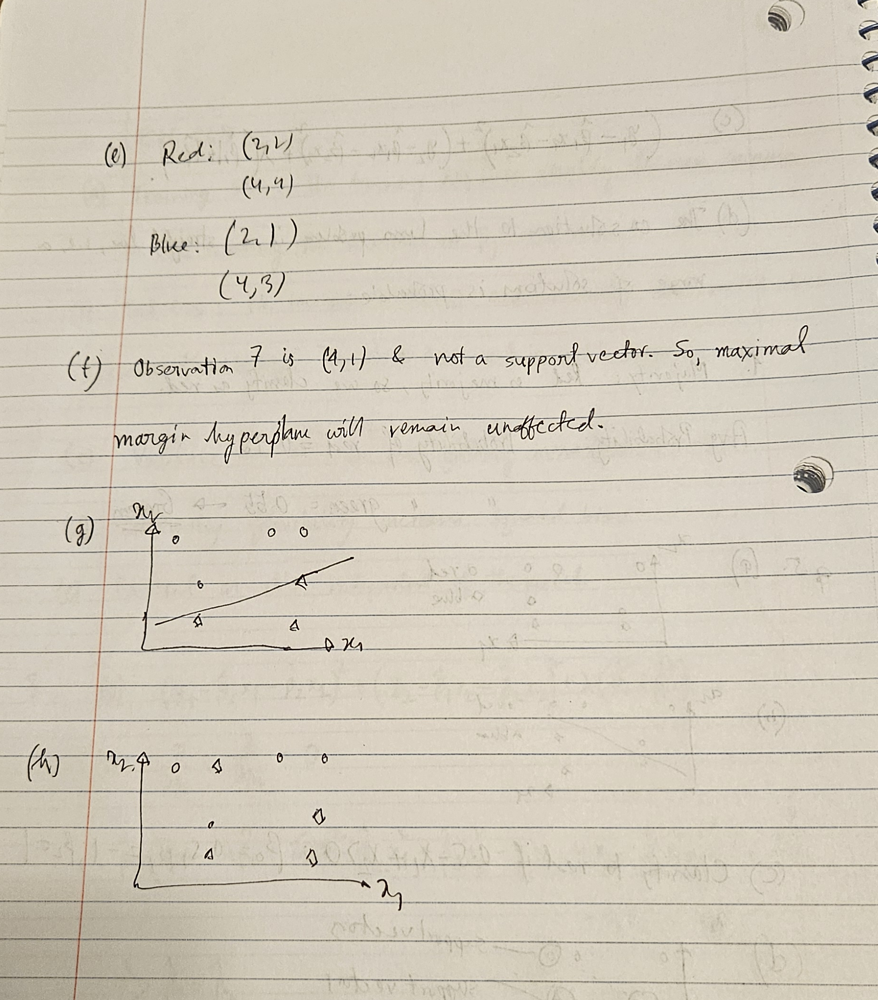

References: https://towardsdatascience.com/the-right-way-of-using-smote-with-cross-validation-92a8d09d00c7
Claude AI for debugging and sample code for syntax.